### Section 1 : Data Loading and Cleaning 

the dataset contains 1,067,371 transactions with 8 columns: Invoice, StockCode, Description, Quantity, InvoiceDate, Price, Customer ID and Country



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("online_retail.csv")

df.head(10)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


In [2]:
df.shape

(1067371, 8)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 136.6 MB


In [4]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [5]:
## Drop rows with missing Customer ID 
df = df.dropna(subset=["Customer ID"])

In [6]:
#only keep rows where Quantity >0
df = df[df["Quantity"] > 0]

# only keep rows with a positive price (zero-price rows are free items or adjustments, not sales)
df = df[df["Price"] > 0]

In [7]:
df = df.drop_duplicates()

In [8]:
df.shape

(779425, 8)

In [9]:
# Convert InvoiceDate to datetime format
df['InvoiceDate'] = pd.to_datetime(df["InvoiceDate"])
df["InvoiceDate"].dtype

dtype('<M8[us]')

**Cleaning steps:**
- Dropped 243,007 rows with missing Customer ID since RFM requires known customers
- Removed negative Quantity rows (cancellations and returns)
- Removed zero-price rows (free items and adjustments, not real sales)
- Removed duplicate rows
- Converted InvoiceDate to datetime format

**After cleaning: 779,425 rows remaining.**

## Section 2: RFM Calculation

Created a new column TotalPrice = Quantity × Price to capture the value of each transaction.

Grouped all transactions by Customer ID and calculated:
- **Recency**: Days since the customer's last purchase (lower = better)
- **Frequency**: Number of unique invoices (higher = better)
- **Monetary**: Total amount spent (higher = better)

A snapshot date was set as one day after the last transaction date to act as the reference point for recency calculation.

Result: 5,878 unique customers with their RFM values.


In [10]:
## Create total transaction value column

df["TotalPrice"] = df["Quantity"] * df["Price"]
df["TotalPrice"].head()

0     83.4
1     81.0
2     81.0
3    100.8
4     30.0
Name: TotalPrice, dtype: float64

In [11]:
# Set snapshot date as one day after the last transaction (acts as "today" for recency calculation)

snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

In [12]:
rfm = df.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('TotalPrice', 'sum')
).reset_index()

rfm.head()

,Customer ID,Recency,Frequency,Monetary
0,12346.0,326,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,2019.40
3,12349.0,19,4,4428.69
4,12350.0,310,1,334.40


In [13]:
rfm.shape

(5878, 4)

## Section 3: RFM Scoring & Segmentation

Each customer was scored 1–4 on Recency, Frequency, and Monetary using quartile-based scoring: pd.qcut for Recency and Monetary, and the Frequency quartiles as fixed cut-offs (many customers share the same order count, so customers with the same number of orders always get the same score). Scores were summed to get a total RFM Score (range 3–12).

Customers were then labelled into 4 segments based on their total score:
- **Champions (10–12):** 1,665 customers (recent, frequent, high spenders)
- **Loyal (7–9):** 1,765 customers (consistent buyers)
- **At Risk (4–6):** 1,825 customers (haven't bought recently or spend little)
- **Lost (3):** 623 customers (inactive, low engagement)

Note: Recency scoring is reversed: lower days since last purchase = higher score, since buying recently is a positive signal.

In [14]:
# Recency is reversed [4,3,2,1] because lower days = bought more recently = better score
rfm["R_score"]= pd.qcut(rfm["Recency"] , q=4, labels=[4,3,2,1])

# Frequency and Monetary are normal [1,2,3,4] — higher values = better score.
# Frequency has many ties (most customers have only 1-3 orders), so it is scored with its
# quartile values as fixed cut-offs: customers with the same number of orders always get the
# same score, and the scores match the Streamlit and web calculators exactly.
f_cuts = rfm["Frequency"].quantile([0.25, 0.5, 0.75]).values
rfm["F_score"] = pd.cut(rfm["Frequency"], bins=[-np.inf, *f_cuts, np.inf], labels=[1,2,3,4])
rfm["M_score"]= pd.qcut(rfm["Monetary"], q=4 , labels=[1,2,3,4])

rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_score,F_score,M_score
0,12346.0,326,12,77556.46,2,4,4
1,12347.0,2,8,4921.53,4,4,4
2,12348.0,75,5,2019.40,3,3,3
3,12349.0,19,4,4428.69,4,3,4
4,12350.0,310,1,334.40,2,1,1


In [15]:
# Calculate total RFM score by summing individual scores

rfm['RFM_Score'] = rfm["R_score"].astype(int) + rfm["F_score"].astype(int) + rfm["M_score"].astype(int)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Score
0,12346.0,326,12,77556.46,2,4,4,10
1,12347.0,2,8,4921.53,4,4,4,12
2,12348.0,75,5,2019.40,3,3,3,9
3,12349.0,19,4,4428.69,4,3,4,11
4,12350.0,310,1,334.40,2,1,1,4


In [16]:
# Assign segment label based on RFM score

def segment_customer(score):

    if score >= 10:
        return 'Champions'
    
    elif score >= 7 :
        return 'Loyal'
    
    elif score >= 4 :
        return "At Risk"
    
    else:
        return "Lost"
    

rfm['Segment'] = rfm['RFM_Score'].apply(segment_customer)
rfm.head()


,Customer ID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Score,Segment
0,12346.0,326,12,77556.46,2,4,4,10,Champions
1,12347.0,2,8,4921.53,4,4,4,12,Champions
2,12348.0,75,5,2019.40,3,3,3,9,Loyal
3,12349.0,19,4,4428.69,4,3,4,11,Champions
4,12350.0,310,1,334.40,2,1,1,4,At Risk


In [17]:
#check segment distribution

rfm["Segment"].value_counts()

Segment
At Risk      1825
Loyal        1765
Champions    1665
Lost          623
Name: count, dtype: int64

## Section 4: Visualisation

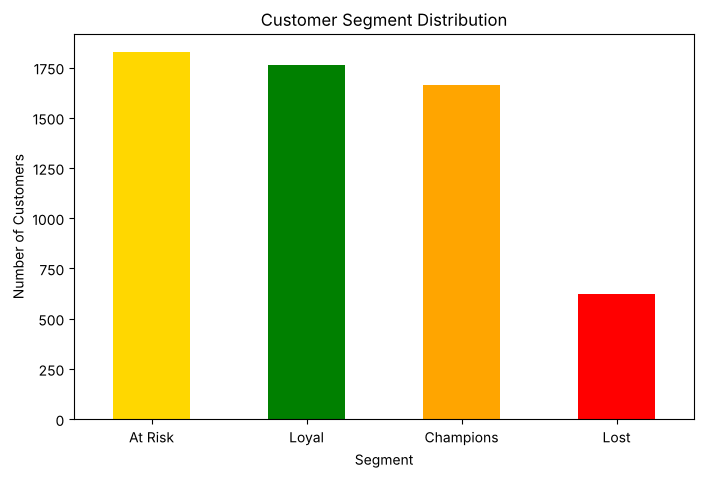

In [18]:


plt.figure(figsize=(8,5))
rfm['Segment'].value_counts().plot(kind='bar', color=['gold','green','orange','red'])
plt.title('Customer Segment Distribution')
plt.xlabel('Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

The customer base is fairly evenly distributed across At Risk (1,825), Loyal (1,765) 
and Champions (1,665) segments, each with roughly 1,650–1,850 customers.

 Lost customers are the smallest group (623). The large At Risk segment is a concern: 31% 
of customers are at risk of churning, which could significantly impact revenue if 
not addressed .

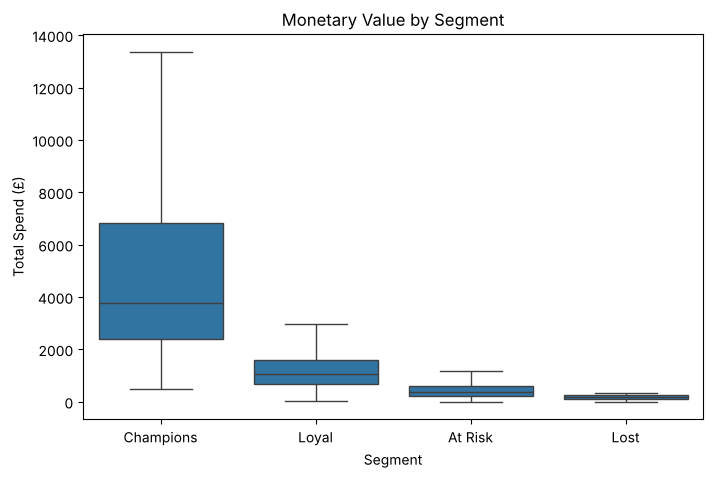

In [19]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Segment', y='Monetary', data=rfm ,showfliers=False)
plt.title('Monetary Value by Segment')
plt.xlabel('Segment')
plt.ylabel('Total Spend (£)')
plt.show()

Champions have significantly higher monetary value with a median spend of ~£3,800, 
compared to Lost customers at under £200. The wide interquartile range for Champions 
suggests a mix of high-value and very high-value customers within this segment.

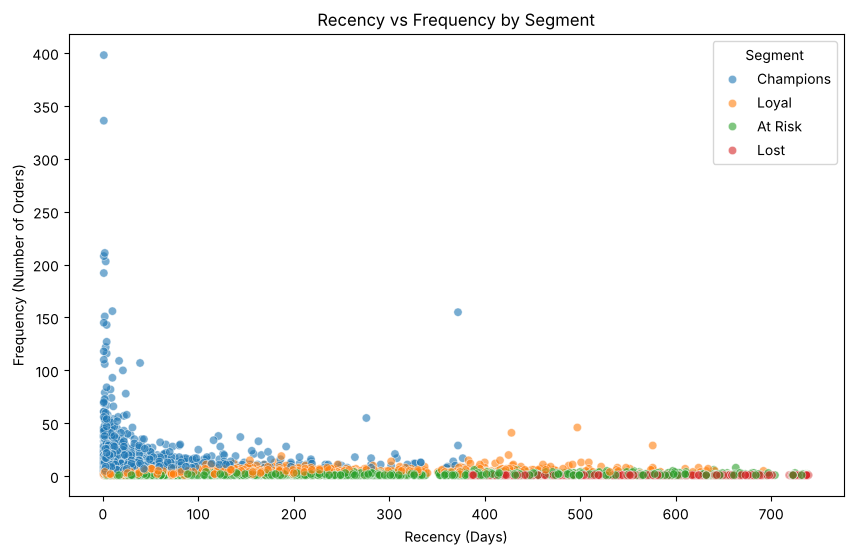

In [20]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='Recency', y='Frequency', hue='Segment', data=rfm, alpha=0.6)
plt.title('Recency vs Frequency by Segment')
plt.xlabel('Recency (Days)')
plt.ylabel('Frequency (Number of Orders)')
plt.show()

Champions cluster in the top-left ,bought recently and very frequently. 
At Risk and Lost customers drift to the right, indicating they haven't 
purchased in a long time. This confirms the RFM segmentation is working correctly.

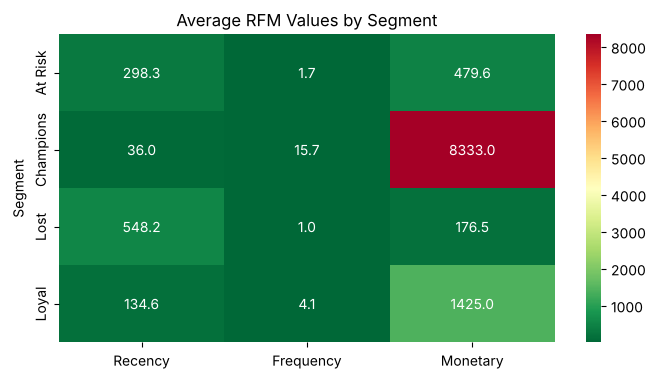

In [21]:
segment_summary = rfm.groupby('Segment')[['Recency','Frequency','Monetary']].mean().round(1)

plt.figure(figsize=(8,4))
sns.heatmap(segment_summary, annot=True, fmt='.1f', cmap='RdYlGn_r')
plt.title('Average RFM Values by Segment')
plt.show()

The heatmap confirms clear differences between segments. Champions average 16 orders 
and £8,333 in spend, while Lost customers average just 1 order and £177. 
Champions last purchased 36 days ago on average, compared to 548 days for Lost customers.


## Section 5: K-Means Clustering
The Elbow Method was used to identify the optimal number of clusters.

In [22]:
# Standardise RFM features before clustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[['Recency','Frequency','Monetary']])

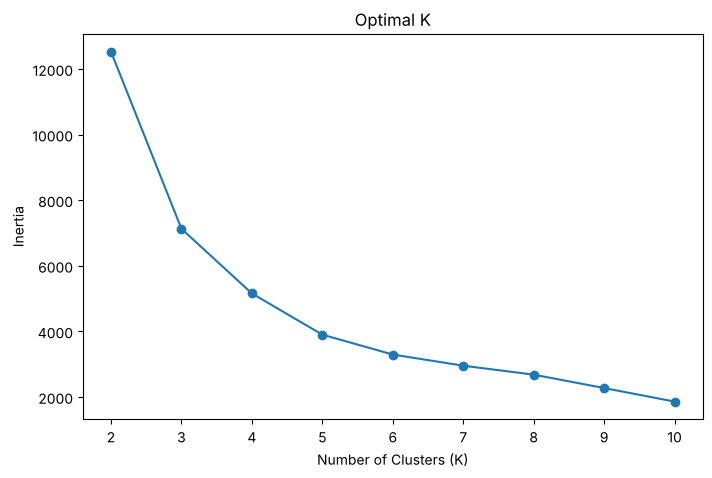

In [23]:

inertia = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(rfm_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(2,11), inertia, marker='o')
plt.title('Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.show()

In [24]:
km = KMeans(n_clusters=4, random_state=42)
rfm['Cluster'] = km.fit_predict(rfm_scaled)
rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Score,Segment,Cluster
0,12346.0,326,12,77556.46,2,4,4,10,Champions,1
1,12347.0,2,8,4921.53,4,4,4,12,Champions,1
2,12348.0,75,5,2019.40,3,3,3,9,Loyal,1
3,12349.0,19,4,4428.69,4,3,4,11,Champions,1
4,12350.0,310,1,334.40,2,1,1,4,At Risk,0


In [25]:
print(rfm.groupby(['Segment', 'Cluster']).size().unstack(fill_value=0))

Cluster       0     1   2  3
Segment                     
At Risk    1047   778   0  0
Champions    15  1611  35  4
Lost        623     0   0  0
Loyal       318  1447   0  0


Comparing K-Means clusters with manual RFM segments:
- **Champions** align well with Cluster 1 (1,611 out of 1,665)
- **Lost** customers all fall into Cluster 0 (all 623)
- **Loyal and At Risk** overlap significantly in Cluster 0 and 1, showing 
  that K-Means struggles to separate middle-tier segments

This confirms that percentile-based RFM scoring produces cleaner, more 
interpretable segments for business use compared to K-Means alone.

## Section 6: Revenue Contribution

Champions represent only 28.3% of customers but contribute 79.9% of total revenue. 
Loyal customers contribute 14.5%, while At Risk and Lost together account for just 5.6%.

This highlights the critical importance of retaining Champion customers:
losing even a small portion of them would significantly impact overall revenue.

In [26]:
revenue_by_segment = rfm.groupby('Segment')['Monetary'].sum()
revenue_pct = (revenue_by_segment / revenue_by_segment.sum() * 100).round(1)
print(revenue_pct)

Segment
At Risk       5.0
Champions    79.9
Lost          0.6
Loyal        14.5
Name: Monetary, dtype: float64


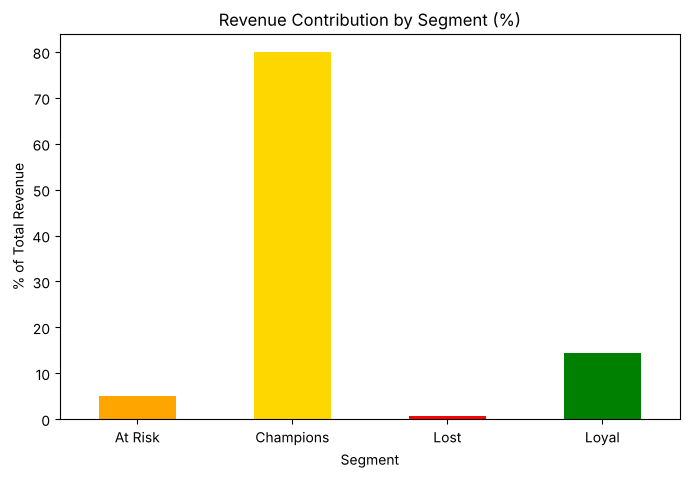

In [27]:
plt.figure(figsize=(8,5))
revenue_pct.plot(kind='bar', color=['orange','gold','red','green'])
plt.title('Revenue Contribution by Segment (%)')
plt.xlabel('Segment')
plt.ylabel('% of Total Revenue')
plt.xticks(rotation=0)
plt.show()

Champions contribute 79.9% of total revenue despite being only 28.3% of the customer base. 
Loyal customers contribute 14.5%, while At Risk and Lost together account for just 5.6%.

Retaining Champion customers should be 
the top business priority, as losing even a small number of them would have a 
significant impact on overall revenue.

## Section 7: Actionable Recommendations

| Segment | Strategy |
|---|---|
| Champions | Reward with loyalty perks, ask for reviews, offer early access to new products, upsell premium items |
| Loyal | Enrol in loyalty programme, send personalised offers, encourage higher spend with bundle deals |
| At Risk | Send win-back email campaign, offer time-limited discount, ask for feedback on why they stopped buying |
| Lost | Low priority , only re-engage with a significant offer, otherwise focus budget on other segments |

In [28]:
with pd.ExcelWriter('rfm_report.xlsx', engine='openpyxl') as writer:
    rfm.to_excel(writer, sheet_name='All Customers', index=False)
    rfm[rfm['Segment']=='Champions'].to_excel(writer, sheet_name='Champions', index=False)
    rfm[rfm['Segment']=='Loyal'].to_excel(writer, sheet_name='Loyal', index=False)
    rfm[rfm['Segment']=='At Risk'].to_excel(writer, sheet_name='At Risk', index=False)
    rfm[rfm['Segment']=='Lost'].to_excel(writer, sheet_name='Lost', index=False)

print("Excel report saved!")

Excel report saved!


In [29]:
# Save quartile thresholds for Streamlit app
r_quartiles = rfm['Recency'].quantile([0.25, 0.5, 0.75]).values
f_quartiles = rfm['Frequency'].quantile([0.25, 0.5, 0.75]).values
m_quartiles = rfm['Monetary'].quantile([0.25, 0.5, 0.75]).values

print("Recency quartiles:", r_quartiles)
print("Frequency quartiles:", f_quartiles)
print("Monetary quartiles:", m_quartiles)

Recency quartiles: [ 26.  96. 380.]
Frequency quartiles: [1. 3. 7.]
Monetary quartiles: [ 342.28   867.74  2248.305]
